In [3]:
import numpy as np
import pandas as pd
import matplotlib as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, confusion_matrix , classification_report
import pickle

In [4]:
df = pd.read_csv('/content/WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [5]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
df.shape

(7043, 21)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [8]:
#droping customer id
df = df.drop(columns = ['customerID'])

In [9]:
df.head(2)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No


In [10]:
#uniquevalues
numerical_value_list = ['tenure','MonthlyCharges','TotalCharges']
for col in df.columns:
  if col not in numerical_value_list:
    print(col,df[col].unique())
    print("-"*50)

gender ['Female' 'Male']
--------------------------------------------------
SeniorCitizen [0 1]
--------------------------------------------------
Partner ['Yes' 'No']
--------------------------------------------------
Dependents ['No' 'Yes']
--------------------------------------------------
PhoneService ['No' 'Yes']
--------------------------------------------------
MultipleLines ['No phone service' 'No' 'Yes']
--------------------------------------------------
InternetService ['DSL' 'Fiber optic' 'No']
--------------------------------------------------
OnlineSecurity ['No' 'Yes' 'No internet service']
--------------------------------------------------
OnlineBackup ['Yes' 'No' 'No internet service']
--------------------------------------------------
DeviceProtection ['No' 'Yes' 'No internet service']
--------------------------------------------------
TechSupport ['No' 'Yes' 'No internet service']
--------------------------------------------------
StreamingTV ['No' 'Yes' 'No internet 

In [11]:
print(df.isnull().sum())

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [12]:
#changing datatype
#df["TotalCharges"] = df["TotalCharges"].astype(float)

In [13]:
df[df["TotalCharges"] == ' ']

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [14]:
len(df[df["TotalCharges"] == ' '])

11

In [15]:
df["TotalCharges"] = df["TotalCharges"].replace({" ":"0.0"})

In [16]:
df["TotalCharges"] = df["TotalCharges"].astype(float)

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [18]:
#checking the distribution of the target
print(df["Churn"].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


**Insights**
1. CustonerId removed as it is not required
2. No Missing Value in the dataset
3. Missing Values in TotalCharges were replaced by 0
4. Class Imbalance is identified in the target

**Exploratory Data Analysis**

In [19]:
df.shape

(7043, 20)

In [20]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [21]:
df.head(2)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No


In [22]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


**Numerical Feature Analysis**

In [23]:
import matplotlib.pyplot as plt

In [24]:
def plot_histogram(df,column_name):

  plt.figure(figsize = (5,3))
  sns.histplot(df[column_name],kde = True)
  plt.title(f"Distribution of {column_name}")

  #calculating the mean and median of the column
  col_mean = df[column_name].mean()
  col_median = df[column_name].median()

  #add vertical line for mean and median
  plt.axvline(col_mean,color = 'red',linestyle = '--',label = 'Mean')
  plt.axvline(col_median,color = 'blue',linestyle = '-',label = 'Median')

  plt.legend()

  plt.show()

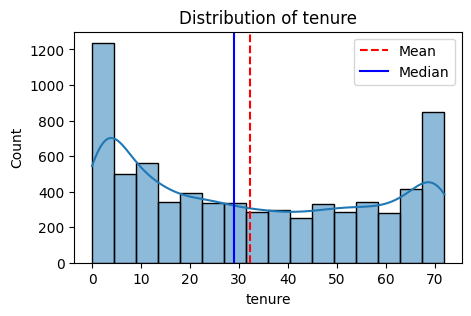

In [25]:
plot_histogram(df, "tenure")

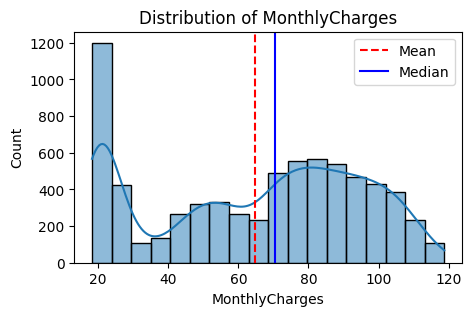

In [26]:
plot_histogram(df,"MonthlyCharges")

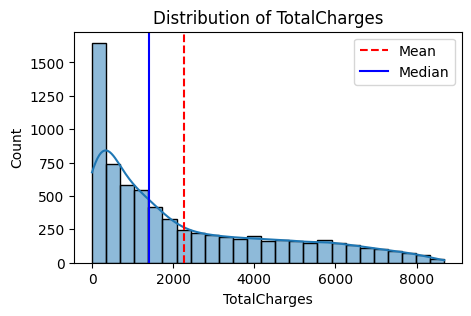

In [27]:
plot_histogram(df,"TotalCharges")

In [28]:
def plot_boxplot(df,column_name):

  plt.figure(figsize = (5,3))
  sns.boxplot(df[column_name])
  plt.title(f"Distribution of {column_name}")
  plt.ylabel(column_name)
  plt.show

**Boxplot for the outliers**

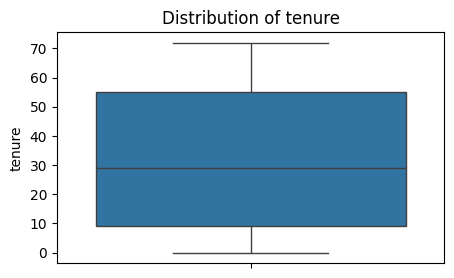

In [29]:
plot_boxplot(df,"tenure")

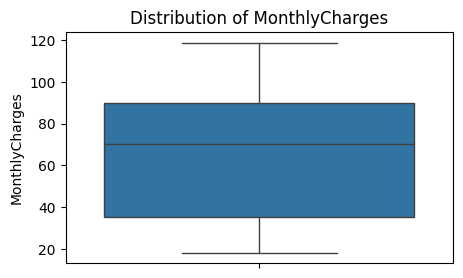

In [30]:
plot_boxplot(df,"MonthlyCharges")

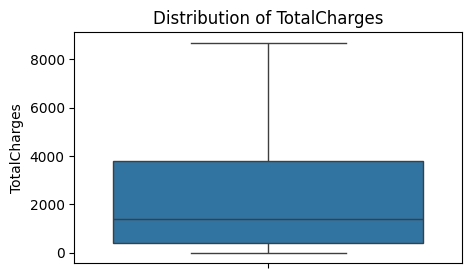

In [31]:
plot_boxplot(df,"TotalCharges")

**Heatmap for the correlation between the numerical data**

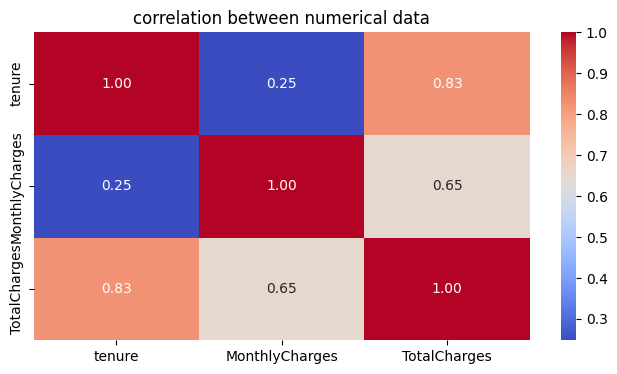

In [32]:
plt.figure(figsize = (8,4))
sns.heatmap(df[["tenure","MonthlyCharges","TotalCharges"]].corr(),annot = True,cmap = "coolwarm",fmt = ".2f")
plt.title("correlation between numerical data")
plt.show()

**Categorical feature analysis**

In [33]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [35]:
object_cols = df.select_dtypes(include= "object").columns.to_list()
object_cols = ["SeniorCitizen"] + object_cols

In [36]:
object_cols

['SeniorCitizen',
 'gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'Churn']

countplot for categorical data

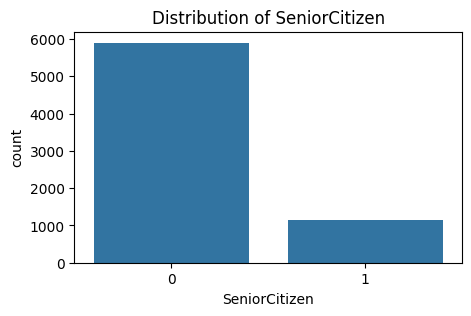

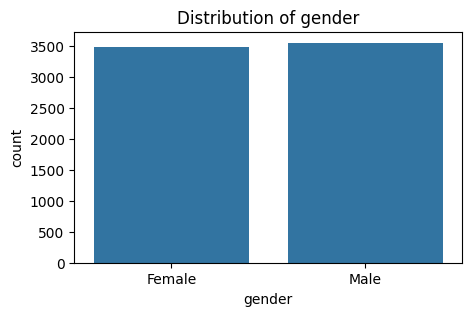

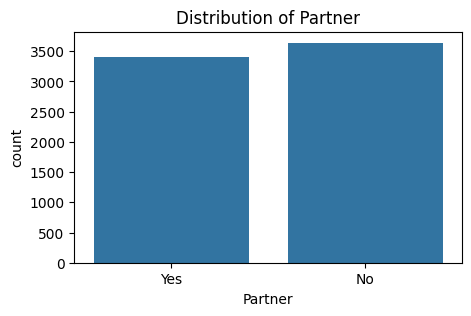

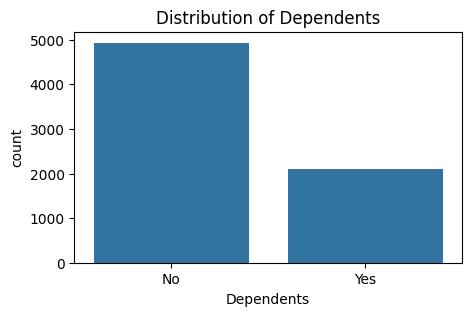

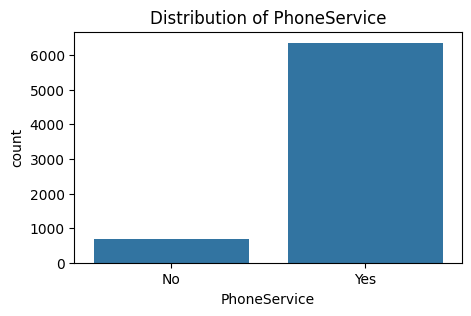

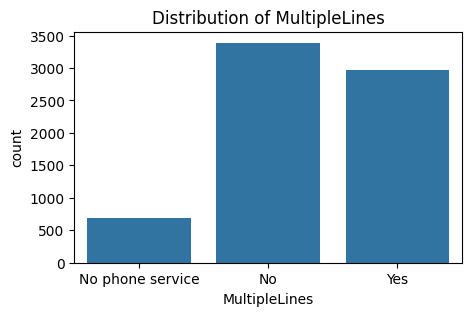

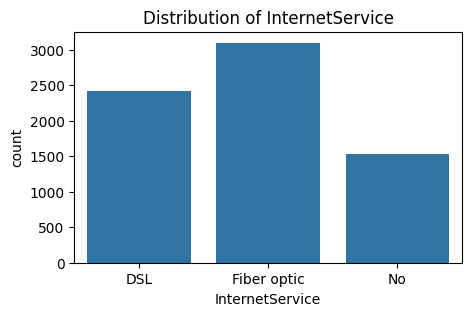

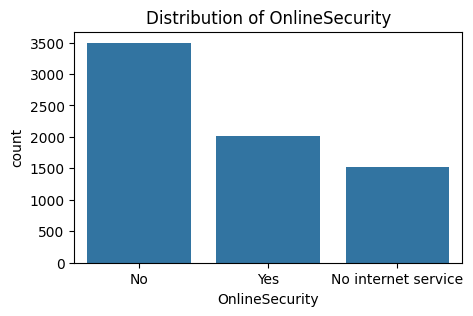

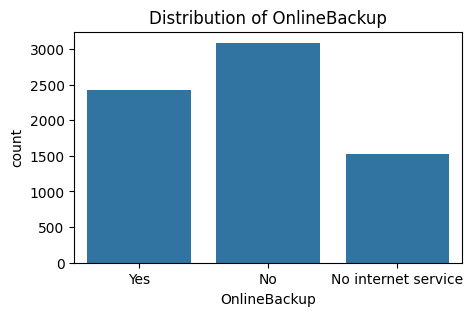

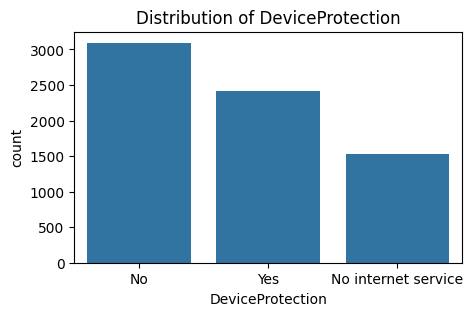

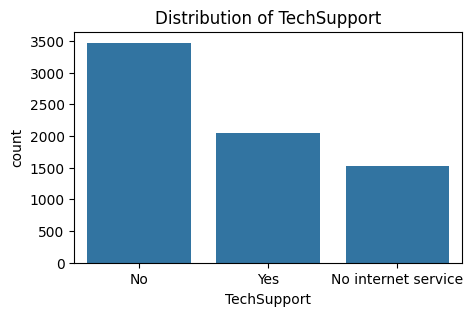

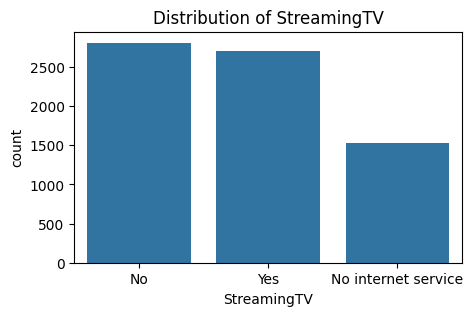

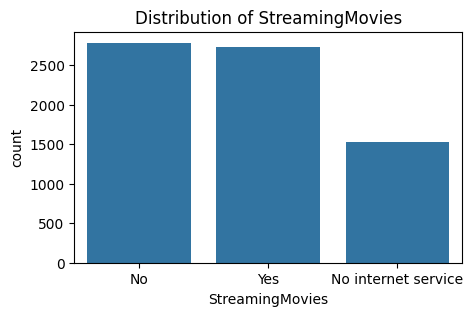

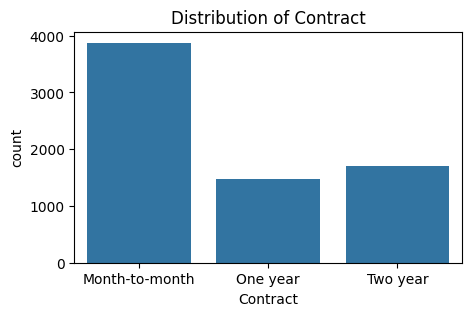

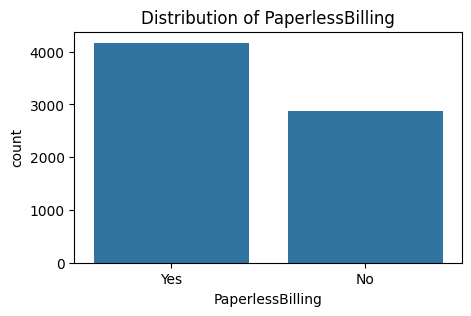

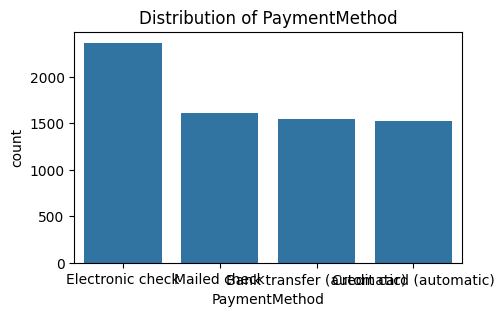

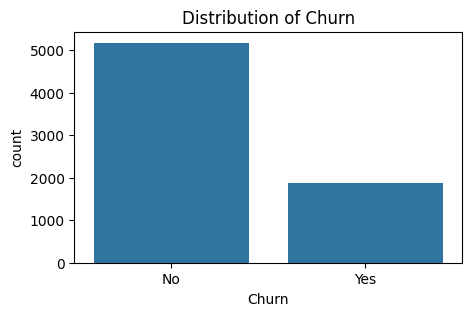

In [37]:
for col in object_cols:
  plt.figure(figsize = (5,3))
  sns.countplot(x = df[col])
  plt.title(f"Distribution of {col}")
  plt.show()

**Data Preprocessing**

In [38]:
df["Churn"] = df["Churn"].replace({"No" : 0 , "Yes" : 1})

/tmp/ipykernel_2534/2897343612.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["Churn"] = df["Churn"].replace({"No" : 0 , "Yes" : 1})


In [39]:
df.head(2)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0


In [40]:
print(df["Churn"].value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


In [41]:
object_columns = df.select_dtypes(include = "object").columns

In [42]:
object_columns

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object')

In [43]:
#initialise a dictionary to save the encoders
encoder = {}

for column in object_columns:
  label_encoder = LabelEncoder()
  df[column] = label_encoder.fit_transform(df[column])
  encoder[column] = label_encoder

#save the encoder to a pickle file
with open("encoder.pkl","wb") as f:
  pickle.dump(encoder,f)

In [44]:
encoder

{'gender': LabelEncoder(),
 'Partner': LabelEncoder(),
 'Dependents': LabelEncoder(),
 'PhoneService': LabelEncoder(),
 'MultipleLines': LabelEncoder(),
 'InternetService': LabelEncoder(),
 'OnlineSecurity': LabelEncoder(),
 'OnlineBackup': LabelEncoder(),
 'DeviceProtection': LabelEncoder(),
 'TechSupport': LabelEncoder(),
 'StreamingTV': LabelEncoder(),
 'StreamingMovies': LabelEncoder(),
 'Contract': LabelEncoder(),
 'PaperlessBilling': LabelEncoder(),
 'PaymentMethod': LabelEncoder()}

In [45]:
df.head(2)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85,0
1,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50,0


**Training and Testing data**

In [46]:
#splitting the features and target
x = df.drop(columns = ["Churn"])
y = df["Churn"]

In [47]:
#split training and test data
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2,random_state = 42)

In [48]:
print(y_train.shape)

(5634,)


In [49]:
print(y_train.value_counts())

Churn
0    4138
1    1496
Name: count, dtype: int64


**Synthetic Minority Oversampling Technique (SMOTE)**
  oversampling

In [50]:
smote = SMOTE(random_state = 42)

In [51]:
x_train_smote,y_train_smote = smote.fit_resample(x_train,y_train)

In [52]:
print(y_train_smote.shape)

(8276,)


In [53]:
print(y_train_smote.value_counts())

Churn
0    4138
1    4138
Name: count, dtype: int64


**Model Training**

In [54]:
#dictionary of models
models = {
    "Decision Tree" : DecisionTreeClassifier(random_state = 42),
    "Random Forest" : RandomForestClassifier(random_state = 42),
    "XGBoost" : XGBClassifier(random_state = 42)
}

In [55]:
#dictionary to store the cross validation results
cv_results = {}

#Perform 5 folds cv for each model
for model_name,model in models.items():
  cv_scores = cross_val_score(model,x_train_smote,y_train_smote,cv = 5,scoring = "accuracy")
  cv_results[model_name] = cv_scores
  print(f"{model_name} cross_validation_accuracy : {np.mean(cv_scores):.2f}")
  print("-"*50)

Decision Tree cross_validation_accuracy : 0.78
--------------------------------------------------
Random Forest cross_validation_accuracy : 0.84
--------------------------------------------------
XGBoost cross_validation_accuracy : 0.83
--------------------------------------------------


In [56]:
cv_results

{'Decision Tree': array([0.68297101, 0.71299094, 0.82175227, 0.83564955, 0.83564955]),
 'Random Forest': array([0.72524155, 0.77824773, 0.90513595, 0.89425982, 0.90090634]),
 'XGBoost': array([0.71135266, 0.74984894, 0.90271903, 0.89607251, 0.89667674])}

Raandom forest gives the highest accuracy with default parameters

In [72]:
rfc = RandomForestClassifier(random_state = 42,max_depth = 16,max_samples=32)
rfc.fit(x_train_smote,y_train_smote)

RandomForestClassifier(max_depth=16, max_samples=32, random_state=42)

**Evaluation**

In [60]:
print(y_test.value_counts())

Churn
0    1036
1     373
Name: count, dtype: int64


In [73]:
y_test_pred = rfc.predict(x_test)

print("Accuracy_score:\n",accuracy_score(y_test,y_test_pred))
print("-"*60)

print("Confusion matrix : \n",confusion_matrix(y_test,y_test_pred))
print("-"*60)

print("Classification report :\n",classification_report(y_test,y_test_pred))
print("-"*60)

Accuracy_score:
 0.7686302342086586
------------------------------------------------------------
Confusion matrix : 
 [[788 248]
 [ 78 295]]
------------------------------------------------------------
Classification report :
               precision    recall  f1-score   support

           0       0.91      0.76      0.83      1036
           1       0.54      0.79      0.64       373

    accuracy                           0.77      1409
   macro avg       0.73      0.78      0.74      1409
weighted avg       0.81      0.77      0.78      1409

------------------------------------------------------------


In [74]:
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold
cv = StratifiedKFold(5, shuffle=True, random_state=42)
models = {
    "No regularization": LogisticRegression(penalty=None, max_iter=2000, class_weight="balanced"),
    "L2 (Ridge)": LogisticRegressionCV(Cs=np.logspace(-3, 2, 20), cv=cv, penalty="l2",
                                       solver="lbfgs", scoring="roc_auc", max_iter=2000,
                                       class_weight="balanced"),
    "L1 (Lasso)": LogisticRegressionCV(Cs=np.logspace(-3, 2, 20), cv=cv, penalty="l1",
                                       solver="saga", scoring="roc_auc", max_iter=5000,
                                       class_weight="balanced", n_jobs=2),
    "Elastic Net": LogisticRegressionCV(Cs=np.logspace(-3, 2, 12), cv=cv, penalty="elasticnet",
                                        solver="saga", l1_ratios=[0.2, 0.5, 0.8],
                                        scoring="roc_auc", max_iter=5000,
                                        class_weight="balanced", n_jobs=2),
}

In [77]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
num = ["tenure", "MonthlyCharges", "TotalCharges"]
cat = [c for c in x.columns if c not in num]
pre = ColumnTransformer([
    ("num", StandardScaler(), num),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat),
])

In [80]:
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, confusion_matrix)
rows, fitted, rocs = [], {}, {}
for name, clf in models.items():
    pipe = Pipeline([("pre", pre), ("clf", clf)]).fit(x_train_smote, y_train_smote)
    yte, Xte = y_test, x_test
    p = pipe.predict_proba(Xte)[:, 1]; pred = (p >= 0.5).astype(int)
    c = pipe.named_steps["clf"]
    C = float(np.ravel(c.C_)[0]) if hasattr(c, "C_") else np.nan
    l1r = float(np.ravel(c.l1_ratio_)[0]) if hasattr(c, "l1_ratio_") and c.l1_ratio_ is not None and np.all(np.array(c.l1_ratio_) != None) else np.nan
    nz = int((np.abs(c.coef_) > 1e-8).sum())
    rows.append(dict(Model=name, C=C, l1_ratio=l1r, NonZeroCoefs=nz,
                     Accuracy=accuracy_score(yte, pred), Precision=precision_score(yte, pred),
                     Recall=recall_score(yte, pred), F1=f1_score(yte, pred),
                     ROC_AUC=roc_auc_score(yte, p)))
    fitted[name] = pipe; rocs[name] = roc_curve(yte, p)

res = pd.DataFrame(rows).round(4)
print(res.to_string(index=False))


            Model        C  l1_ratio  NonZeroCoefs  Accuracy  Precision  Recall     F1  ROC_AUC
No regularization      NaN       NaN            30    0.7857     0.5791  0.6971 0.6326   0.8520
       L2 (Ridge)  54.5559       NaN            30    0.7835     0.5762  0.6890 0.6276   0.8517
       L1 (Lasso)  16.2378       NaN            30    0.7842     0.5775  0.6890 0.6284   0.8520
      Elastic Net 100.0000       0.8            30    0.7842     0.5775  0.6890 0.6284   0.8520


In [81]:
best = res.sort_values("ROC_AUC", ascending=False).iloc[0]["Model"]
print("Best:", best)
pipe = fitted[best]
names = pipe.named_steps["pre"].get_feature_names_out()
coef = pd.Series(pipe.named_steps["clf"].coef_[0], index=names).sort_values()
print(coef.head(8).round(3)); print(coef.tail(8).round(3))
p = pipe.predict_proba(Xte)[:, 1]
cm = confusion_matrix(yte, (p >= 0.5).astype(int)); print(cm)

Best: No regularization
cat__InternetService_2   -62.079
num__tenure               -2.231
cat__Contract_2           -1.663
cat__PhoneService_1       -1.466
cat__InternetService_1    -1.248
cat__OnlineSecurity_2     -1.165
cat__TechSupport_2        -1.038
cat__Contract_1           -0.796
dtype: float64
num__TotalCharges           1.784
num__MonthlyCharges         2.161
cat__StreamingMovies_1      6.932
cat__DeviceProtection_1     8.332
cat__StreamingTV_1          8.548
cat__OnlineSecurity_1      11.660
cat__TechSupport_1         13.755
cat__OnlineBackup_1        14.074
dtype: float64
[[847 189]
 [113 260]]


In [82]:
ths = np.arange(0.2, 0.81, 0.05)
f1s = [f1_score(yte, (p >= t).astype(int)) for t in ths]
print("Best F1 threshold:", round(ths[int(np.argmax(f1s))], 2), round(max(f1s), 4))

# ---- 5. Plots ----
plt.figure(figsize=(5.5, 4.5))
for n, (fpr, tpr, _) in rocs.items(): plt.plot(fpr, tpr, label=n)
plt.plot([0, 1], [0, 1], "k--", lw=.8); plt.xlabel("FPR"); plt.ylabel("TPR")
plt.title("ROC curves (test set)"); plt.legend(fontsize=8); plt.tight_layout()
plt.savefig("roc.png", dpi=150); plt.close()

top = pd.concat([coef.head(10), coef.tail(10)])
plt.figure(figsize=(6.5, 5.5))
plt.barh(top.index, top.values, color=["#c0392b" if v > 0 else "#2874a6" for v in top.values])
plt.axvline(0, color="k", lw=.8); plt.title(f"Top coefficients - {best}")
plt.xlabel("Coefficient (log-odds, standardized)"); plt.tight_layout()
plt.savefig("coef.png", dpi=150); plt.close()

Best F1 threshold: 0.45 0.6477


In [62]:
#save the trained model as a pickle file

model_data = {"Model" : rfc,"Feature_name": x.columns.tolist()}


with open("customer_churn_prediction_model.pkl","wb") as f:
  pickle.dump(model_data,f)

In [63]:
#load the saved model and the encoders
with open("customer_churn_prediction_model.pkl","rb") as f:
  model_data = pickle.load(f)

  loaded_model = model_data["Model"]
  feature_names = model_data["Feature_name"]

In [64]:
print(feature_names)

['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


In [65]:
input_data= {
    "gender": "Female",
    "SeniorCitizen": 0,
    "Partner": "Yes",
    "Dependents": "No",
    "tenure": 1,
    "PhoneService": "No",
    "MultipleLines": "No phone service",
    "InternetService": "DSL",
    "OnlineSecurity": "No",
    "OnlineBackup": "Yes",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "No",
    "StreamingMovies": "No",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 29.85,
    "TotalCharges": 29.85,
}

input_data_df = pd.DataFrame([input_data])

print(input_data_df)

with open ("encoder.pkl","rb") as f:
  encoders = pickle.load(f)

#encode categorical data using the saved encoders
for col,encoder in encoders.items():
  input_data_df[col] = encoder.transform(input_data_df[col])

   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0     Yes         No       1           No   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No          No          No              No  Month-to-month   

  PaperlessBilling     PaymentMethod  MonthlyCharges  TotalCharges  
0              Yes  Electronic check           29.85         29.85  


In [66]:
print(input_data_df)

   gender  SeniorCitizen  Partner  Dependents  tenure  PhoneService  \
0       0              0        1           0       1             0   

   MultipleLines  InternetService  OnlineSecurity  OnlineBackup  \
0              1                0               0             2   

   DeviceProtection  TechSupport  StreamingTV  StreamingMovies  Contract  \
0                 0            0            0                0         0   

   PaperlessBilling  PaymentMethod  MonthlyCharges  TotalCharges  
0                 1              2           29.85         29.85  


In [67]:
prediction = loaded_model.predict(input_data_df)
pred_prob = loaded_model.predict_proba(input_data_df)

print(prediction)
print(f"Prediction : {'Churn' if prediction[0] == 1 else 'No churn'}")
print(f"Prediction Probability : {pred_prob}")

[0]
Prediction : No churn
Prediction Probability : [[0.78 0.22]]
